<a href="https://colab.research.google.com/github/pravalikamamidisetti/EDA-Project/blob/main/External.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import the libraries


In [248]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as plt

Loaded the E-commerce Reviews Classification CSV file using Pandas.


In [202]:
df=pd.read_csv("/content/ecommerce_reviews_classification.csv")
df

,review_id,rating_dup,user_id,sentiment,helpful_votes,rating,review_text,verified_purchase,product_id
0,R90000,5.0,20105.0,positive,125.0,5.0,Good roduct,No,1033.0
1,R90001,5.0,NaN,positive,80.0,5.0,Terrible quality,No,1080.0
2,R90002,4.0,20356.0,positive,21.0,4.0,NaN,No,1074.0
3,R90003,5.0,20007.0,positive,189.0,5.0,Excellent!,Yes,1092.0
4,R90004,5.0,20261.0,positive,55.0,5.0,Not as expected,Yes,1033.0
...,...,...,...,...,...,...,...,...,...
260,R90056,NaN,20386.0,neutral,14.0,NaN,Terrible quality,Yes,1017.0
261,R90153,4.0,20087.0,positive,197.0,4.0,Terrible quality,No,1064.0
262,R90032,5.0,20481.0,positive,43.0,5.0,Value for money,YES,1088.0
263,R90096,5.0,20173.0,positive,74.0,5.0,Would buy again,No,1080.0


Checked the number of rows, columns, data types and column names.


In [203]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          251 non-null    object 
 1   rating_dup         256 non-null    float64
 2   user_id            252 non-null    float64
 3   sentiment          252 non-null    object 
 4   helpful_votes      248 non-null    float64
 5   rating             256 non-null    float64
 6   review_text        245 non-null    object 
 7   verified_purchase  246 non-null    object 
 8   product_id         253 non-null    float64
dtypes: float64(5), object(4)
memory usage: 18.8+ KB


checked no.of duplicate rows

In [204]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 15


dropped the duplicate rows


In [205]:
df = df.drop_duplicates()

In [206]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


dropped the rating dup column becuase it is the duplicate of the rating column

In [207]:
df = df.drop(columns=["rating_dup"])

In [208]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          236 non-null    object 
 1   user_id            237 non-null    float64
 2   sentiment          237 non-null    object 
 3   helpful_votes      233 non-null    float64
 4   rating             243 non-null    float64
 5   review_text        230 non-null    object 
 6   verified_purchase  233 non-null    object 
 7   product_id         240 non-null    float64
dtypes: float64(4), object(4)
memory usage: 17.6+ KB


cleaning the data in sentiment columns

In [209]:
df["sentiment"].unique()

array(['positive', 'neutral', 'negative', nan], dtype=object)

In [210]:
df["sentiment"]=df["sentiment"].fillna(df["sentiment"].mode()[0])
df["sentiment"]

,sentiment
0,positive
1,positive
2,positive
3,positive
4,positive
...,...
245,positive
246,positive
247,positive
248,positive


In [211]:
df["sentiment"].unique()

array(['positive', 'neutral', 'negative'], dtype=object)

In [212]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          236 non-null    object 
 1   user_id            237 non-null    float64
 2   sentiment          250 non-null    object 
 3   helpful_votes      233 non-null    float64
 4   rating             243 non-null    float64
 5   review_text        230 non-null    object 
 6   verified_purchase  233 non-null    object 
 7   product_id         240 non-null    float64
dtypes: float64(4), object(4)
memory usage: 17.6+ KB


cleaning the data in helpful_votes columns

In [213]:
df["helpful_votes"].unique()

array([125.,  80.,  21., 189.,  55.,  85., 122., 199., 110.,   7.,  61.,
        77., 151.,  14., 155., 149.,  30.,  86.,  68., 108., 166.,  nan,
        39., 182.,  70.,  63.,  43.,  37., 116., 148.,   3., 159.,  54.,
        92., 187.,  58.,  93.,  66.,   4.,  82.,  71., 126.,  26.,  12.,
       133.,  64.,  40., 132.,   0.,  47., 181., 157.,  59.,  65., 173.,
        51.,  34., 120.,  41., 183.,  44., 150.,  28.,  56.,  18., 177.,
       134., 138., 194.,  27.,  88.,  74., 129.,  75., 188., 113., 152.,
        94.,  53., 144., 175.,   1.,  79.,  33., 128.,  99.,  97., 185.,
        49., 100., 118., 139., 114.,  72., 192., 165.,  35., 171., 196.,
       180., 140., 131.,  69., 178., 101., 197.,  10., 109., 186.,  60.,
       167., 154.,  15.,   6., 179., 127.,   5., 119., 193.,  84.,  57.,
        23., 158., 168.,  67., 106.,   9., 164.,  20., 123., 112.,  96.,
       137.,  81., 111., 130., 146.,   8., 176.])


cleaning the data in rating column

In [215]:
df["rating"].unique()

array([ 5.,  4.,  3.,  1.,  2., nan])

In [216]:
df["rating"]=df["rating"].fillna(df["rating"].mode()[0])
df["rating"]

,rating
0,5.0
1,5.0
2,4.0
3,5.0
4,5.0
...,...
245,3.0
246,4.0
247,5.0
248,4.0


In [217]:
df["rating"].unique()

array([5., 4., 3., 1., 2.])

cleaning the data in review_text column

In [218]:
df["review_text"].unique()

array(['Good roduct', 'Terrible quality', nan, 'Excellent!',
       'Not as expected', 'Would buy again', 'Value for money',
       'EXCELLENT!', 'Value fo money', 'Good product', 'Not as expcted',
       'Would uy again', 'Not s expected', 'Good poduct',
       'Value for mone', 'NOT AS EXPECTED', 'TERRIBLE QUALITY',
       'Excelent!', 'Value for mony', 'Ecellent!', 'WOULD BUY AGAIN',
       'Not as expecte', 'Good produc', 'Terrible uality',
       'VALUE FOR MONEY', 'Would buy aain', 'Terible quality',
       'Goodproduct'], dtype=object)

In [219]:
df['review_text'] = df['review_text'].replace({
    'Good roduct': 'Good product',
    'Good poduct': 'Good product',
    'Good produc': 'Good product',
    'Goodproduct': 'Good product',

    'Excelent!': 'Excellent!',
    'Ecellent!': 'Excellent!',
    'EXCELLENT!': 'Excellent!',

    'Terrible uality': 'Terrible quality',
    'Terible quality': 'Terrible quality',
    'TERRIBLE QUALITY': 'Terrible quality',

    'Not as expcted': 'Not as expected',
    'Not s expected': 'Not as expected',
    'Not as expecte': 'Not as expected',
    'NOT AS EXPECTED': 'Not as expected',

    'Would uy again': 'Would buy again',
    'Would buy aain': 'Would buy again',
    'WOULD BUY AGAIN': 'Would buy again',

    'Value fo money': 'Value for money',
    'Value for mone': 'Value for money',
    'Value for mony': 'Value for money',
    'VALUE FOR MONEY': 'Value for money'
})

In [220]:
df['review_text']=df['review_text'].fillna(df['review_text'].mode()[0])
df["review_text"]

,review_text
0,Good product
1,Terrible quality
2,Terrible quality
3,Excellent!
4,Not as expected
...,...
245,Terrible quality
246,Excellent!
247,Good product
248,Excellent!


In [221]:
df['review_text'].unique()

array(['Good product', 'Terrible quality', 'Excellent!',
       'Not as expected', 'Would buy again', 'Value for money'],
      dtype=object)

In [222]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          236 non-null    object 
 1   user_id            237 non-null    float64
 2   sentiment          250 non-null    object 
 3   helpful_votes      233 non-null    float64
 4   rating             250 non-null    float64
 5   review_text        250 non-null    object 
 6   verified_purchase  233 non-null    object 
 7   product_id         240 non-null    float64
dtypes: float64(4), object(4)
memory usage: 17.6+ KB


cleaning the data in verified purchase column

In [223]:
df["verified_purchase"].unique()

array(['No', 'Yes', nan, 'Ye', 'Ys', 'YES', 'es', 'NO', 'o', 'N'],
      dtype=object)

In [224]:
df['verified_purchase'] = df['verified_purchase'].replace({
    'Ye': 'Yes',
    'Ys': 'Yes',
    'YES': 'Yes',
    'es': 'Yes',
    'NO': 'No',
    'o': 'No',
    'N': 'No'})

In [225]:
df["verified_purchase"]=df["verified_purchase"].fillna(df["verified_purchase"].mode()[0])
df["verified_purchase"]

,verified_purchase
0,No
1,No
2,No
3,Yes
4,Yes
...,...
245,Yes
246,Yes
247,Yes
248,No


In [226]:
df["verified_purchase"].unique()

array(['No', 'Yes'], dtype=object)

In [227]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          236 non-null    object 
 1   user_id            237 non-null    float64
 2   sentiment          250 non-null    object 
 3   helpful_votes      233 non-null    float64
 4   rating             250 non-null    float64
 5   review_text        250 non-null    object 
 6   verified_purchase  250 non-null    object 
 7   product_id         240 non-null    float64
dtypes: float64(4), object(4)
memory usage: 17.6+ KB


filling the id columns with the null value first and then filling them using the arrange function because the id columns cannot have same values

In [228]:
cols = ['review_id', 'user_id', 'product_id']
df[cols] = np.nan
df['review_id'] = np.arange(1, len(df) + 1)
df['user_id'] = np.arange(1, len(df) + 1)
df['product_id'] = np.arange(1, len(df) + 1)

In [229]:
df['review_id'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [230]:
df['user_id'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [231]:
df['product_id'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [232]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          250 non-null    int64  
 1   user_id            250 non-null    int64  
 2   sentiment          250 non-null    object 
 3   helpful_votes      233 non-null    float64
 4   rating             250 non-null    float64
 5   review_text        250 non-null    object 
 6   verified_purchase  250 non-null    object 
 7   product_id         250 non-null    int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 17.6+ KB


finding outliers in all the columns

<Axes: xlabel='review_id'>

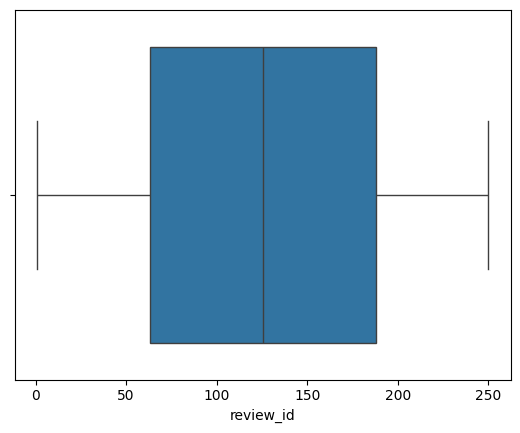

In [233]:
sns.boxplot(data=df,x="review_id")

<Axes: xlabel='user_id'>

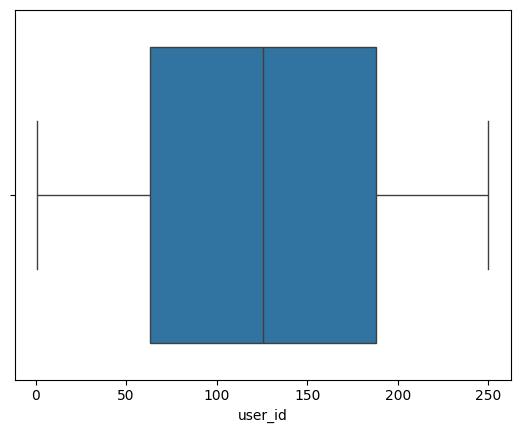

In [234]:
sns.boxplot(data=df,x="user_id")

<Axes: xlabel='sentiment'>

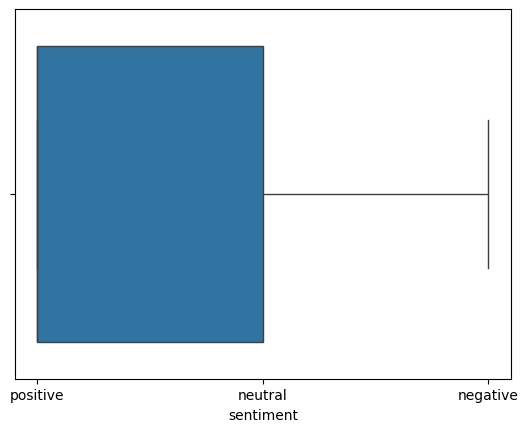

In [235]:
sns.boxplot(data=df, x="sentiment")

<Axes: xlabel='helpful_votes'>

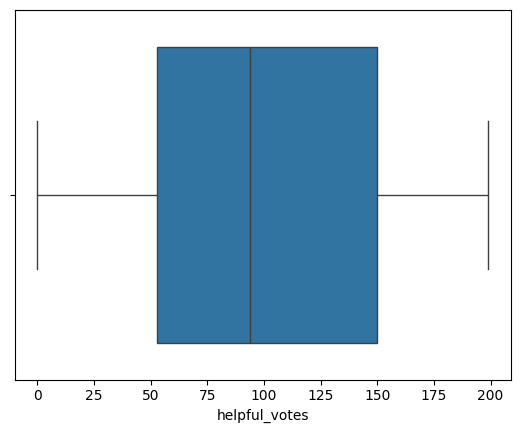

In [236]:
sns.boxplot(data=df, x="helpful_votes")

<Axes: xlabel='rating'>

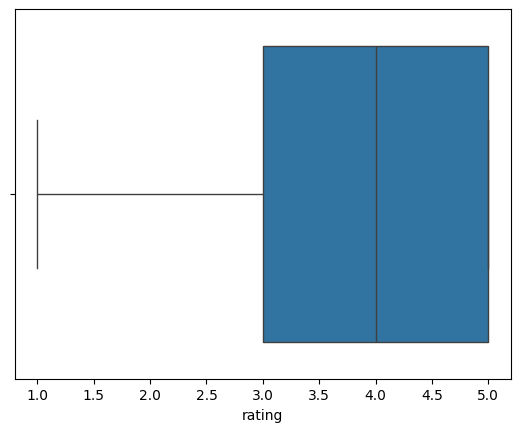

In [237]:
sns.boxplot(data=df, x="rating")

<Axes: xlabel='review_text'>

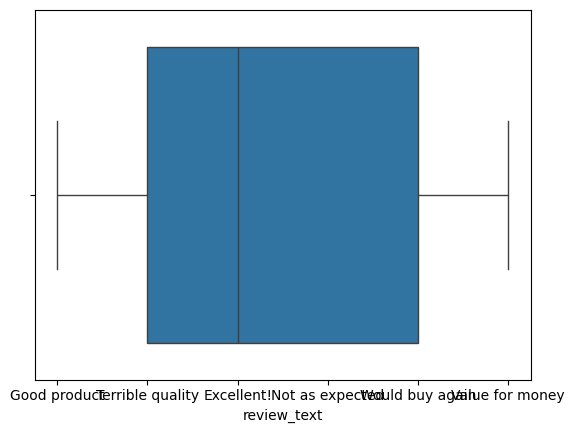

In [238]:
sns.boxplot(data=df, x="review_text")

<Axes: xlabel='verified_purchase'>

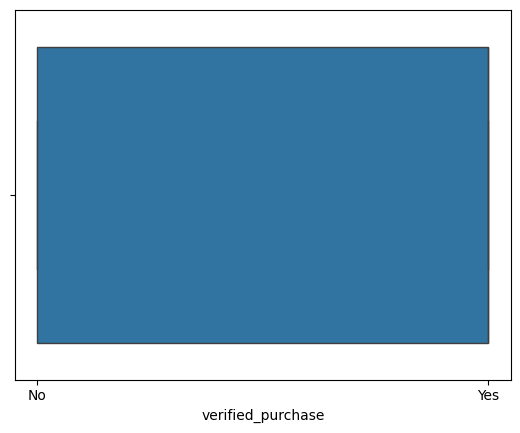

In [239]:
sns.boxplot(data=df,x="verified_purchase")

<Axes: xlabel='product_id'>

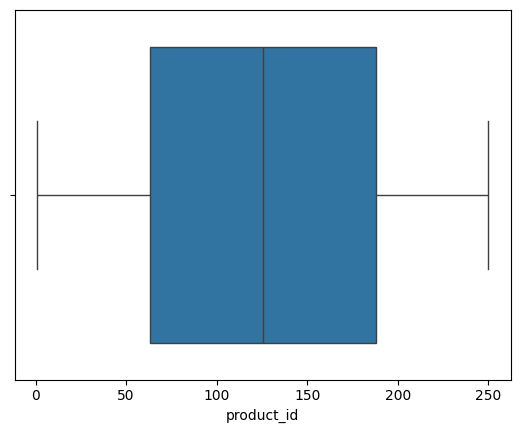

In [240]:
sns.boxplot(data=df,x="product_id")

In [241]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          250 non-null    int64  
 1   user_id            250 non-null    int64  
 2   sentiment          250 non-null    object 
 3   helpful_votes      233 non-null    float64
 4   rating             250 non-null    float64
 5   review_text        250 non-null    object 
 6   verified_purchase  250 non-null    object 
 7   product_id         250 non-null    int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 17.6+ KB


In [242]:
out_cols = ['review_id', 'rating', 'helpful_votes', 'user_id', 'product_id']
for col in out_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(col, ":", len(outliers), "Outliers")

review_id : 0 Outliers
rating : 0 Outliers
helpful_votes : 0 Outliers
user_id : 0 Outliers
product_id : 0 Outliers


save the preprocessed data set

In [243]:
df.to_csv("preprocessed_ecommerce_reviews.csv", index=False)
print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


load the pre processed data set

In [244]:
df1=pd.read_csv("/content/preprocessed_ecommerce_reviews.csv")
df1

,review_id,user_id,sentiment,helpful_votes,rating,review_text,verified_purchase,product_id
0,1,1,positive,125.0,5.0,Good product,No,1
1,2,2,positive,80.0,5.0,Terrible quality,No,2
2,3,3,positive,21.0,4.0,Terrible quality,No,3
3,4,4,positive,189.0,5.0,Excellent!,Yes,4
4,5,5,positive,55.0,5.0,Not as expected,Yes,5
...,...,...,...,...,...,...,...,...
245,246,246,positive,81.0,3.0,Terrible quality,Yes,246
246,247,247,positive,176.0,4.0,Excellent!,Yes,247
247,248,248,positive,93.0,5.0,Good product,Yes,248
248,249,249,positive,132.0,4.0,Excellent!,No,249


In [245]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          250 non-null    int64  
 1   user_id            250 non-null    int64  
 2   sentiment          250 non-null    object 
 3   helpful_votes      233 non-null    float64
 4   rating             250 non-null    float64
 5   review_text        250 non-null    object 
 6   verified_purchase  250 non-null    object 
 7   product_id         250 non-null    int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 15.8+ KB


UNIVARIATE ANALYSIS


1.Analyzed the distribution of customer ratings using a histogram

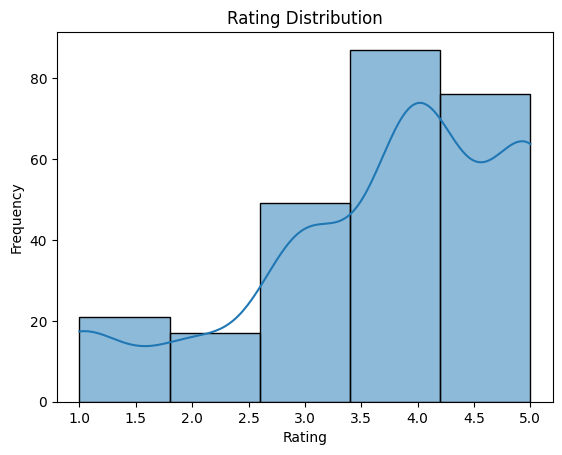

In [251]:
import matplotlib.pyplot as plt
sns.histplot(df['rating'], bins=5, kde=True)
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

2.Count-Plot:Analyzed the number of positive, negative and neutral customer reviews.

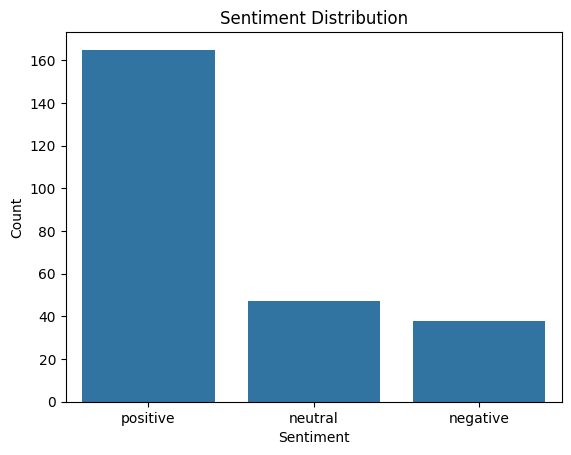

In [252]:
import matplotlib.pyplot as plt
sns.countplot(data=df, x="sentiment")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

3.Pie-chart:Analyzed the percentage of verified and non-verified purchases.

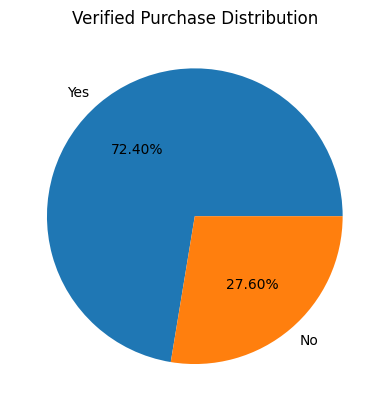

In [254]:
import matplotlib.pyplot as plt
counts = df['verified_purchase'].value_counts()
plt.pie(counts, labels=counts.index,autopct='%1.2f%%')
plt.title("Verified Purchase Distribution")
plt.show()

4.Density-plot:tudied the density and shape of the helpful votes distribution

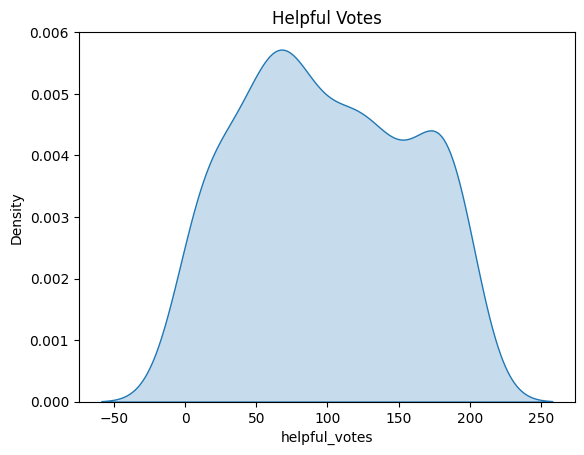

In [255]:
sns.kdeplot(data=df, x='helpful_votes', fill=True)
plt.title("Helpful Votes")
plt.show()

5.Violin-plot:Visualized the distribution and density of helpful votes

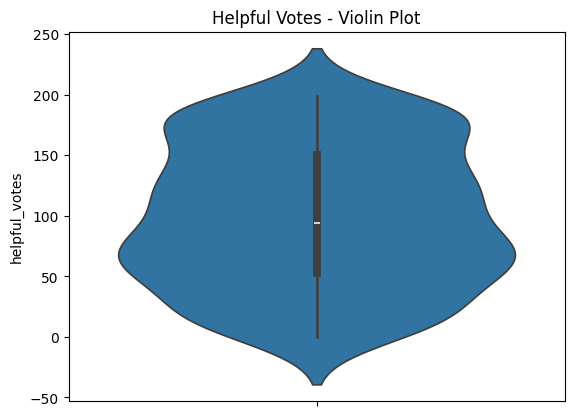

In [256]:
sns.violinplot(y=df['helpful_votes'])
plt.title("Helpful Votes - Violin Plot")
plt.show()

BIVARIATE ANALYSIS

1.Scatter-plot:Analyzed the relationship between customer ratings and helpful votes

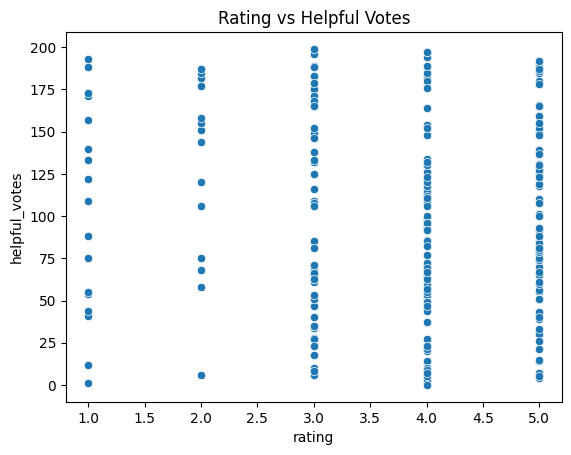

In [257]:
sns.scatterplot(data=df, x='rating', y='helpful_votes')
plt.title("Rating vs Helpful Votes")
plt.show()

2.Bar-plot:Compared the average customer rating across different sentiment categories.

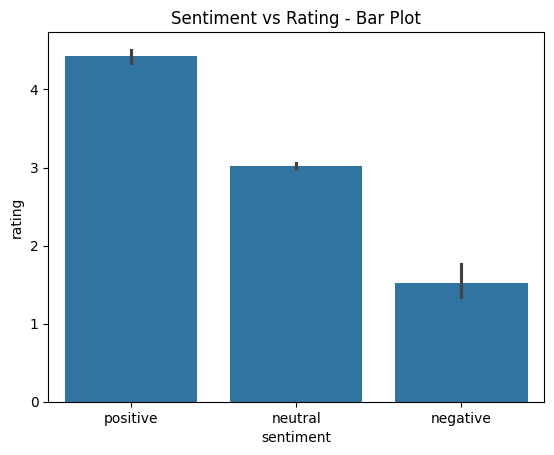

In [258]:
sns.barplot(data=df, x='sentiment', y='rating')
plt.title("Sentiment vs Rating - Bar Plot")
plt.show()

3.Count Plot with Hue:Compared sentiment categories based on verified purchase status.

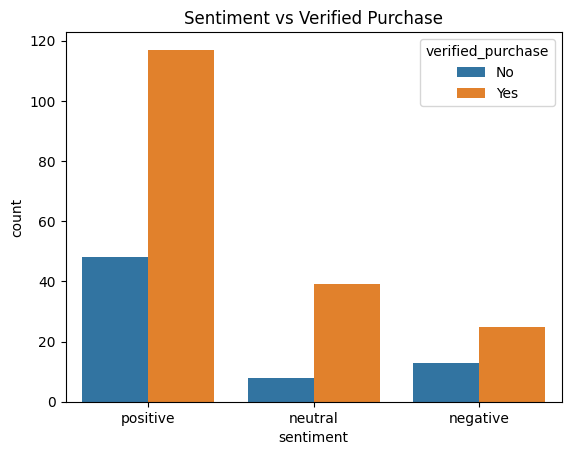

In [266]:
sns.countplot(data=df, x='sentiment',hue='verified_purchase')
plt.title("Sentiment vs Verified Purchase")
plt.show()

4.Violin Plot:Compared the distribution of helpful votes across different sentiment categories.

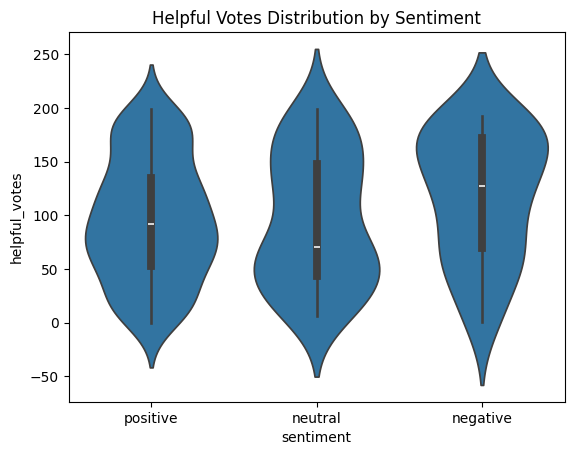

In [267]:
sns.violinplot(data=df, x="sentiment", y="helpful_votes")
plt.title("Helpful Votes Distribution by Sentiment")
plt.show()

MULTIVARIATE ANALYSIS

1.Pair Plot-Analyzed the relationships between rating, helpful votes and sentiment using a pair plot to understand patterns among multiple variables.

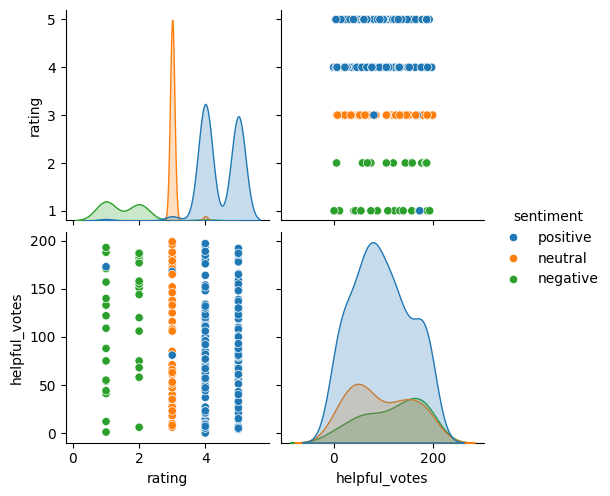

In [264]:
sns.pairplot(data=df, vars=["rating", "helpful_votes"], hue="sentiment")

2.Heatmap-Analyzed the correlations among multiple numerical variables using a correlation matrix and visualized their relationships through a heatmap.

<Axes: >

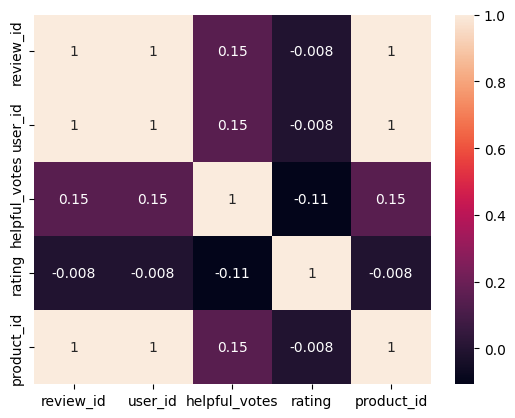

In [265]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

FINAL ANALYSIS REPORT

1.The E-commerce Reviews dataset was successfully loaded, explored and preprocessed by handling missing values, removing duplicate records and cleaning inconsistent data.

2.Missing numerical values were handled using median, while categorical values were handled using mode.

3.Outlier detection was performed using the IQR method and also the box plot is used to check the outliers and no outliers were detected in the selected numerical columns.

4.Univariate analysis was performed using five different visualizations to understand individual variable distributions.

5.Bivariate analysis was performed using four different visualizations to identify relationships between two variables.

6.Multivariate analysis was performed using pair plots and correlation heatmaps to study relationships among multiple variables.

7.Overall, the analysis helped understand customer ratings, sentiments, helpful votes, review patterns and verified purchase behaviour.